**Notebook Criado por:** MSc. Eng. Paulo Silva  
**Notebook Criado em:** 12 / 11 / 2026  
**Última Atualização:** 17 / 11 / 2026  

**Obs:** Este notebook foi desenvolvido sob auxílio de ferramentas de IA.

# **Aula 08 — Problema 1D inverso com geração de calor**

## Identificação de $C=\dot q/k$ com uma PINN normalizada

Neste notebook, a temperatura no interior da parede é conhecida em alguns pontos, mas o parâmetro

$$
C=\frac{\dot q}{k}
$$

é desconhecido. A PINN deverá aprender simultaneamente o campo de temperatura e o valor de $C$.

### Por que os dados são necessários?

A física e as condições de contorno não identificam $C$ de forma única. Para qualquer valor escolhido de $C$, existe uma solução

$$
T(x)=T_s+\frac{C}{2}x(L-x)
$$

que satisfaz a equação e as duas condições $T(0)=T(L)=T_s$. As temperaturas nas superfícies são iguais para toda essa família de soluções. Portanto, o resíduo físico pode ser pequeno para diferentes pares formados por um campo $T(x)$ e um parâmetro $C$.

As observações internas informam a curvatura real do perfil e tornam o parâmetro identificável. Em um experimento, esses valores poderiam ser fornecidos por termopares. Aqui usaremos dados sintéticos da solução analítica para verificar se o procedimento recupera um valor conhecido.

> A solução analítica será usada para gerar os dados e avaliar o resultado. O valor verdadeiro de $C$ não será fornecido à PINN.

Este exemplo segue a estratégia do problema inverso de difusão da documentação do DeepXDE: um parâmetro criado com `dde.Variable`, observações impostas com `PointSetBC` e o parâmetro incluído em `external_trainable_variables`.

## **1. Formulação física e o que pode ser identificado**

Para uma parede plana, estacionária e unidimensional, com propriedades constantes e geração volumétrica uniforme,

$$k\frac{d^2T}{dx^2}+\dot q=0, \qquad 0 < x < L.$$

Dividindo por $k$,

$$\frac{d^2T}{dx^2}+C=0, \qquad C=\frac{\dot q}{k},$$

com

$$T(0)=T(L)=T_s.$$

* Este experimento identifica diretamente a razão $C=\dot q/k$.
* Se $k$ for conhecido, podemos calcular $\dot q=Ck$.
* Se $\dot q$ for conhecido, podemos calcular $k=\dot q/C$.

Com apenas este campo de temperatura, $k$ e $\dot q$ não podem ser estimados independentemente, pois diferentes pares podem produzir a mesma razão $C$.

## **2. Normalização sem utilizar o parâmetro desconhecido**

Definimos

$$
\xi=\frac{x}{L},
\qquad
\theta=\frac{T-T_s}{\Delta T_{\mathrm{dados}}}.
$$

A escala $\Delta T_{\mathrm{dados}}$ será calculada a partir da maior temperatura de excesso observada. Essa escolha usa somente dados disponíveis e não exige conhecer $C$.

Como

$$
\frac{d^2T}{dx^2}=\frac{\Delta T_{\mathrm{dados}}}{L^2}\frac{d^2\theta}{d\xi^2},
$$

a equação normalizada é

$$
\frac{d^2\theta}{d\xi^2}+\overline C=0,
\qquad
\overline C=\frac{CL^2}{\Delta T_{\mathrm{dados}}}.
$$

A **PINN aprenderá $\overline C$**. Depois do treinamento, recuperaremos o parâmetro dimensional por

$$
C=\overline C\frac{\Delta T_{\mathrm{dados}}}{L^2}.
$$

In [1]:
# Se necessário no Google Colab, descomente:
# %pip -q install deepxde torch
!pip -q install deepxde torch

In [2]:
import os

# O backend deve ser definido antes da importação do DeepXDE.
os.environ["DDE_BACKEND"] = "pytorch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import deepxde as dde
import matplotlib.pyplot as plt
import numpy as np

dde.config.set_default_float("float64")
dde.config.set_random_seed(1234)

print("Backend utilizado:", dde.backend.backend_name)

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Set the default float type to float64
Backend utilizado: pytorch


## **3. Problema de referência e dados sintéticos**

Os valores verdadeiros abaixo representam o experimento sintético. Eles serão usados para gerar as observações e, ao final, verificar a estimativa. A função que define o resíduo da PINN não receberá `C_REF`.

In [3]:
# Propriedades usadas somente para construir o experimento sintético
L = 1.0              # comprimento da parede [m]
Ts = 500.0           # temperatura das superfícies [K]
q_dot_ref = 15000.0  # geração verdadeira [W/m³]
k_ref = 150.0        # condutividade verdadeira [W/(m K)]
C_REF = q_dot_ref / k_ref

# Chute inicial informado ao otimizador, propositalmente distante do valor real
C_INICIAL = 30.0     # [K/m²]

# Configuração didática do treinamento
ITERATIONS = 15000
NUM_DOMAIN = 200
NUM_BOUNDARY = 40
NUM_TEST = 400

def temperatura_analitica(x):
    """Solução dimensional usada para gerar e validar os dados."""
    x = np.asarray(x)
    return Ts + 0.5 * C_REF * x * (L - x)

x_eval = np.linspace(0.0, L, 401).reshape(-1, 1)
T_ref = temperatura_analitica(x_eval)

# Nove sensores internos. O ponto central está incluído.
x_obs = np.linspace(0.1 * L, 0.9 * L, 9).reshape(-1, 1)
T_obs = temperatura_analitica(x_obs)

print(f"C verdadeiro, oculto da PINN: {C_REF:.6g} K/m²")
print(f"Chute inicial de C:           {C_INICIAL:.6g} K/m²")
print(f"Temperatura máxima:           {np.max(T_ref):.6g} K")

C verdadeiro, oculto da PINN: 100 K/m²
Chute inicial de C:           30 K/m²
Temperatura máxima:           512.5 K


In [4]:
# A escala térmica vem das medições, sem utilizar C_REF.
delta_T_dados = np.max(np.abs(T_obs - Ts))

if delta_T_dados == 0:
    raise ValueError("Os dados não apresentam variação de temperatura.")

xi_eval = x_eval / L
xi_obs = x_obs / L
theta_obs = (T_obs - Ts) / delta_T_dados

C_adim_inicial = C_INICIAL * L**2 / delta_T_dados

print(f"Escala obtida dos dados: ΔT_dados = {delta_T_dados:.6g} K")
print(f"Máximo observado de theta:       {np.max(theta_obs):.6g}")
print(f"Chute inicial de C_barra:        {C_adim_inicial:.6g}")

Escala obtida dos dados: ΔT_dados = 12.5 K
Máximo observado de theta:       1
Chute inicial de C_barra:        2.4


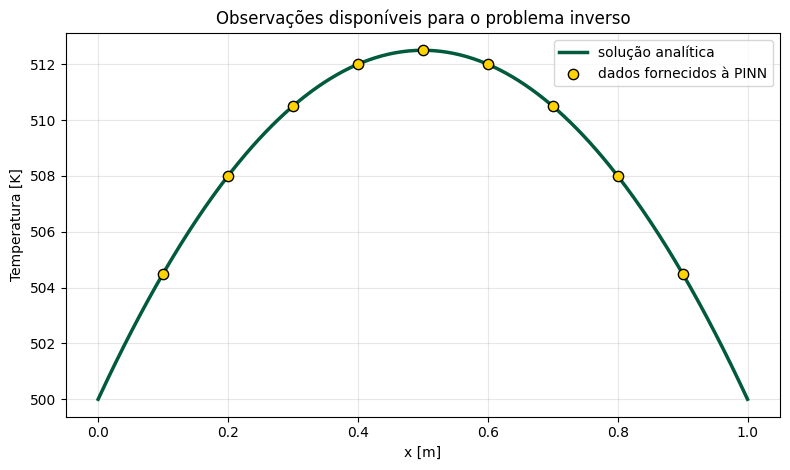

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(x_eval[:, 0], T_ref[:, 0], color="#005A3C", linewidth=2.5,
        label="solução analítica")
ax.scatter(x_obs[:, 0], T_obs[:, 0], color="#FFD300", edgecolor="black",
           s=55, zorder=3, label="dados fornecidos à PINN")
ax.set_title("Observações disponíveis para o problema inverso")
ax.set_xlabel("x [m]")
ax.set_ylabel("Temperatura [K]")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## **4. PINN inversa no DeepXDE**

A variável `C_adim` é independente dos pesos e vieses da rede, mas será atualizada pelo mesmo otimizador. A função de perda possui três contribuições:

$$
\mathcal L=\mathcal L_{\mathrm{EDO}}+\mathcal L_{\mathrm{CC}}+\mathcal L_{\mathrm{dados}}.
$$

- $\mathcal L_{\mathrm{EDO}}$ força $\theta''+\overline C=0$ nos pontos internos;
- $\mathcal L_{\mathrm{CC}}$ força $\theta(0)=\theta(1)=0$;
- $\mathcal L_{\mathrm{dados}}$ compara a saída da rede com as observações internas.

Os pontos observados também são adicionados como `anchors`, fazendo com que o resíduo físico seja avaliado nessas posições.

In [6]:
geom = dde.geometry.Interval(0.0, 1.0)

# Parâmetro desconhecido que será treinado junto com a rede.
C_adim = dde.Variable(C_adim_inicial)

def pde_inversa(xi, theta):
    d2theta_dxi2 = dde.grad.hessian(theta, xi, i=0, j=0)
    return d2theta_dxi2 + C_adim

def boundary(x, on_boundary):
    return on_boundary

def theta_nula(x):
    return np.zeros((len(x), 1))

bc = dde.icbc.DirichletBC(geom, theta_nula, boundary)
observacoes = dde.icbc.PointSetBC(xi_obs, theta_obs, component=0)

data = dde.data.PDE(geom, pde_inversa, [bc, observacoes],
    num_domain=NUM_DOMAIN, num_boundary=NUM_BOUNDARY,
    anchors=xi_obs, num_test=NUM_TEST,
)

net = dde.nn.FNN([1] + [32] * 3 + [1], "tanh", "Glorot uniform",)
model = dde.Model(data, net)
model.compile("adam", lr=1e-3, external_trainable_variables=C_adim,)

parametros_rede = sum(p.numel() for p in model.net.parameters())
print(f"Parâmetros da rede: {parametros_rede}")
print(f"Parâmetros treináveis totais: {parametros_rede + 1}")

Compiling model...
'compile' took 6.039791 s

Parâmetros da rede: 2209
Parâmetros treináveis totais: 2210


## **5. Acompanhamento e treinamento**

O callback padrão `VariableValue` imprime periodicamente o valor de $\overline C$. O callback auxiliar abaixo armazena a mesma trajetória para que possamos visualizar a convergência do parâmetro após o treinamento.

In [7]:
class HistoricoParametro(dde.callbacks.Callback):
    def __init__(self, variavel, period=100):
        super().__init__()
        self.variavel = variavel
        self.period = period
        self.iteracoes = []
        self.valores = []

    def _valor_atual(self):
        return float(self.variavel.detach().cpu().item())

    def _registrar(self):
        iteracao = int(self.model.train_state.iteration)
        if not self.iteracoes or iteracao != self.iteracoes[-1]:
            self.iteracoes.append(iteracao)
            self.valores.append(self._valor_atual())

    def on_train_begin(self):
        self._registrar()

    def on_epoch_end(self):
        if self.model.train_state.iteration % self.period == 0:
            self._registrar()


historico_C = HistoricoParametro(C_adim, period=100)
mostrar_C = dde.callbacks.VariableValue(C_adim, period=500, precision=6)

inicio = time.perf_counter()
losshistory, train_state = model.train(
    iterations=ITERATIONS,
    callbacks=[historico_C, mostrar_C],
    display_every=500,
    verbose=1,
)
tempo_treinamento = time.perf_counter() - inicio

print(f"Tempo de treinamento: {tempo_treinamento:.2f} s")

Training model...

Step      Train loss                        Test loss                         Test metric
0         [5.73e+00, 1.61e-03, 5.46e-01]    [5.72e+00, 1.61e-03, 5.46e-01]    []  
0 [2.400000e+00]


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


500       [1.82e-03, 6.65e-02, 9.23e-02]    [1.93e-03, 6.65e-02, 9.23e-02]    []  
500 [2.317120e+00]
1000      [1.41e-03, 6.55e-02, 9.11e-02]    [1.58e-03, 6.55e-02, 9.11e-02]    []  
1000 [2.357113e+00]
1500      [1.20e-03, 6.41e-02, 8.92e-02]    [1.39e-03, 6.41e-02, 8.92e-02]    []  
1500 [2.416904e+00]
2000      [1.11e-03, 6.22e-02, 8.66e-02]    [1.32e-03, 6.22e-02, 8.66e-02]    []  
2000 [2.498538e+00]
2500      [1.07e-03, 5.94e-02, 8.37e-02]    [1.27e-03, 5.94e-02, 8.37e-02]    []  
2500 [2.604953e+00]
3000      [1.02e-03, 5.69e-02, 7.92e-02]    [1.21e-03, 5.69e-02, 7.92e-02]    []  
3000 [2.739522e+00]
3500      [9.58e-04, 5.34e-02, 7.42e-02]    [1.13e-03, 5.34e-02, 7.42e-02]    []  
3500 [2.905657e+00]
4000      [8.85e-04, 4.96e-02, 6.82e-02]    [1.05e-03, 4.96e-02, 6.82e-02]    []  
4000 [3.105898e+00]
4500      [8.14e-04, 4.46e-02, 6.21e-02]    [9.62e-04, 4.46e-02, 6.21e-02]    []  
4500 [3.341221e+00]
5000      [7.35e-04, 3.96e-02, 5.51e-02]    [8.66e-04, 3.96e-02, 5.51e-02]

## **6. Recuperação de $C$ e avaliação da solução**

A rede fornece $\theta(\xi)$ e o parâmetro treinável fornece $\overline C$. As grandezas dimensionais são recuperadas por

$$
T=T_s + \Delta T_{\mathrm{dados}} \theta,
\qquad
C=\overline C\frac{\Delta T_{\mathrm{dados}}}{L^2}.
$$

O erro relativo do campo será calculado com a temperatura de excesso $T-T_s$. Usar a temperatura absoluta faria o nível de $500\,\mathrm{K}$ dominar a norma e poderia produzir um erro relativo artificialmente pequeno.

In [8]:
theta_pred = model.predict(xi_eval)
T_pred = Ts + delta_T_dados * theta_pred
erro_T = T_pred - T_ref

C_adim_estimado = float(C_adim.detach().cpu().item())
C_estimado = C_adim_estimado * delta_T_dados / L**2

erro_relativo_C = 100.0 * abs(C_estimado - C_REF) / abs(C_REF)
rmse_T = np.sqrt(np.mean(erro_T**2))
erro_max_T = np.max(np.abs(erro_T))
erro_l2_excesso = (np.linalg.norm((T_pred - Ts) - (T_ref - Ts))
    / np.linalg.norm(T_ref - Ts))

print(f"C verdadeiro:              {C_REF:.8f} K/m²")
print(f"C estimado pela PINN:      {C_estimado:.8f} K/m²")
print(f"Erro relativo em C:        {erro_relativo_C:.4f} %")
print(f"Erro L2 no excesso de T:   {erro_l2_excesso:.4e}")
print(f"RMSE da temperatura:       {rmse_T:.4e} K")
print(f"Erro máximo de temperatura:{erro_max_T: .4e} K")

C verdadeiro:              100.00000000 K/m²
C estimado pela PINN:      98.01921675 K/m²
Erro relativo em C:        1.9808 %
Erro L2 no excesso de T:   1.1323e-02
RMSE da temperatura:       1.0323e-01 K
Erro máximo de temperatura: 1.5465e-01 K


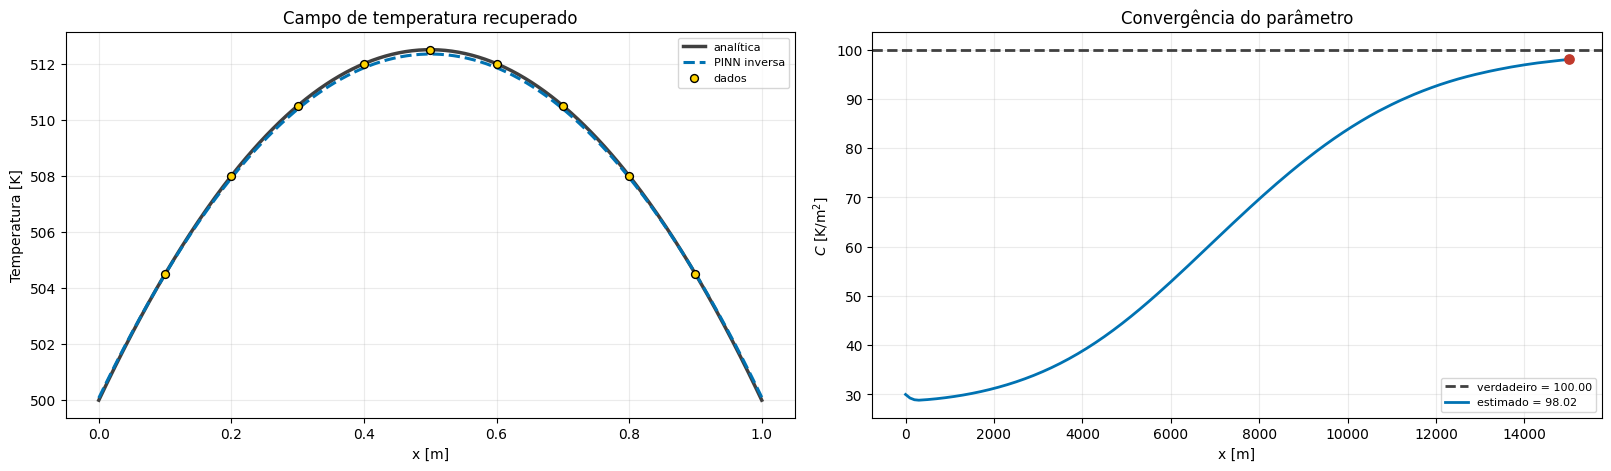

In [13]:
x = x_eval[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), constrained_layout=True)

axes[0].plot(x, T_ref[:, 0], color="0.25", linewidth=2.5, label="analítica")
axes[0].plot(x, T_pred[:, 0], color="#0072B2", linestyle="--",
             linewidth=2.2, label="PINN inversa")
axes[0].scatter(x_obs[:, 0], T_obs[:, 0], color="#FFD300",
                edgecolor="black", s=32, zorder=3, label="dados")
axes[0].set_title("Campo de temperatura recuperado")
axes[0].set_ylabel("Temperatura [K]")
axes[0].legend(fontsize=8)

iteracoes_C = np.asarray(historico_C.iteracoes)
valores_C = (np.asarray(historico_C.valores) * delta_T_dados / L**2)
axes[1].axhline(C_REF, color="0.25", linestyle="--", linewidth=2,
                label=f"verdadeiro = {C_REF:.2f}")
axes[1].plot(iteracoes_C, valores_C, color="#0072B2", linewidth=2,
             label=f"estimado = {C_estimado:.2f}")
axes[1].scatter(iteracoes_C[-1], valores_C[-1], color="#C0392B",
                s=45, zorder=3)
axes[1].set_title("Convergência do parâmetro")
axes[1].set_xlabel("Iterações do Adam")
axes[1].set_ylabel(r"$C$ [K/m$^2$]")
axes[1].legend(fontsize=8)

for ax in axes[:2]:
    ax.set_xlabel("x [m]")

for ax in axes:
    ax.grid(True, alpha=0.25)

plt.show()

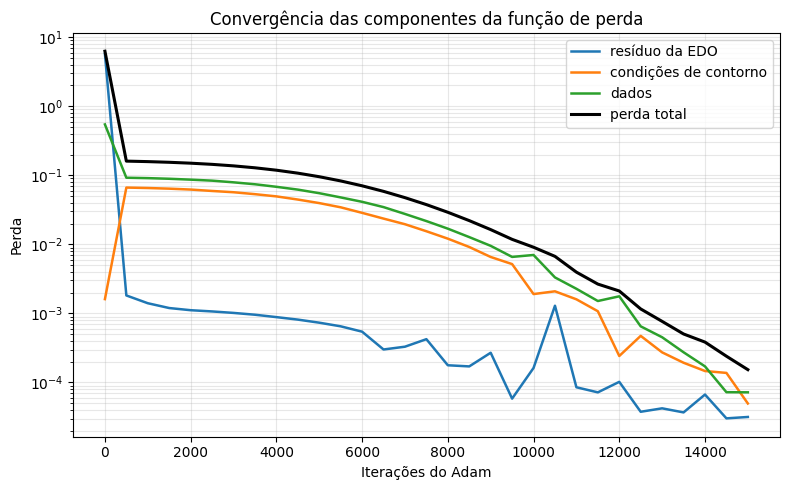

In [10]:
steps = np.asarray(losshistory.steps)
losses = np.asarray(losshistory.loss_train, dtype=float)
rotulos = ["resíduo da EDO", "condições de contorno", "dados"]

fig, ax = plt.subplots(figsize=(8, 5))
for i, rotulo in enumerate(rotulos):
    ax.semilogy(steps, losses[:, i], linewidth=1.8, label=rotulo)

ax.semilogy(steps, np.sum(losses, axis=1), color="black",
            linewidth=2.2, label="perda total")
ax.set_title("Convergência das componentes da função de perda")
ax.set_xlabel("Iterações do Adam")
ax.set_ylabel("Perda")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## **7. Interpretação dos resultados**

- As condições de contorno fixam as extremidades do perfil, mas não informam sua curvatura. Por isso, elas não bastam para identificar $C$.
- Os dados internos acrescentam a informação que falta e permitem aprender simultaneamente $\theta(\xi)$ e $\overline C$.
- A normalização utiliza a amplitude observada nos dados, mantendo entradas e saídas em escalas adequadas sem usar o parâmetro verdadeiro.
- O valor dimensional de $C$ é recuperado somente após o treinamento.
- O problema identifica a razão $\dot q/k$. Para estimar $\dot q$ ou $k$ individualmente, o outro valor precisa ser conhecido ou deve existir informação experimental adicional.
- Em dados experimentais, ruído, quantidade de sensores e suas posições afetam a incerteza da estimativa. O experimento sintético sem ruído serve como primeira verificação da implementação.

Se for necessário garantir matematicamente que $C>0$, uma extensão consiste em treinar $\log C$ e usar uma transformação exponencial no resíduo. Neste primeiro exemplo, mantemos a parametrização direta empregada na documentação do DeepXDE.